In [49]:
# at resolution that of the finest resolution gridded product (CHIRTS at 5566m)

In [50]:
#Libraries

import math
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyproj import Proj
from scipy.optimize import curve_fit
from scipy.spatial.distance import pdist
from scipy.ndimage import gaussian_filter
from scipy.interpolate import griddata

import rasterio
from rasterio.enums import Resampling
from rasterio.warp import calculate_default_transform, reproject

import geostatspy.geostats as geostats
from pykrige.ok import OrdinaryKriging


In [51]:
# %%
# ── Section 1: User Configuration ─────────────────────────────────────────────

import pandas as pd

# ── Per-variable input files ───────────────────────────────────────────────────
VARIABLE_CONFIGS = {
    "tmax": {
        "insitu_csv": r"..\Data\Processed\Insitu\insitu_maxtemp_1991_2020.csv",
        "train_csv":  r"..\Data_Temp\Processed\Split_stations\train_station_tmax.csv",
        "test_csv":   r"..\Data_Temp\Processed\Split_stations\test_station_tmax.csv",
        "value_col":  "max_temp",
    },
    "tmin": {
        "insitu_csv": r"..\Data\Processed\Insitu\insitu_mintemp_1991_2020.csv",
        "train_csv":  r"..\Data_Temp\Processed\Split_stations\train_station_tmin.csv",
        "test_csv":   r"..\Data_Temp\Processed\Split_stations\test_station_tmin.csv",
        "value_col":  "min_temp",
    },
}

# station_metadata_df removed — elevation now comes from the DEM, sampled
# at each station's lon/lat (already present in the insitu CSVs as
# lat/long → renamed to y/x in Section 4). If you still want metadata
# fields like DISTRICT for diagnostics later, reload it separately; it's
# no longer a pipeline dependency.

# ── Grid template & DEM ────────────────────────────────────────────────────────
template_wgs84_path = r"..\Data_Temp\Datasets\CHIRTS\CHIRTS_tmax_20010101.tif"
dem_path = r"..\Data\Datasets\DEM_1km\DEM_1km_elevation_mean.tif"

# ── Calibration & processing periods ───────────────────────────────────────────
calibration_start_year = 2001
calibration_end_year   = 2005
krig_start_day = pd.Timestamp("2001-01-01")
krig_end_day   = pd.Timestamp("2005-12-31")

# ── Variogram fitting constants ────────────────────────────────────────────────
sill_target = 0.8
fix_range_fallback_km = 150.0   # placeholder — recalibrate after Section 6 residual variograms are fit

# ── Trend-fitting minimum ──────────────────────────────────────────────────────
min_stations_for_trend = 10

# ── Output ──────────────────────────────────────────────────────────────────────
output_dir = r"..\Data_Temp\Datasets\Kriging_daily"
temp_dir   = r"..\Data_Temp\Datasets\Kriging_daily\Temp"
var_dir    = r"..\Data_Temp\Datasets\Kriging_daily\Temp\Variogram_analysis"
nodata_out = -9999.0

In [52]:
# %%
# ── Section 2: Fixed Constants ────────────────────────────────────────────────

import os

UTM_PROJ = "+proj=utm +zone=45 +ellps=WGS84 +datum=WGS84 +units=m +no_defs"

SEASONS = {
    'winter':       [12, 1, 2],
    'pre_monsoon':  [3, 4, 5],
    'monsoon':      [6, 7, 8, 9],
    'post_monsoon': [10, 11],
}

COLORS = {
    'spherical':   'steelblue',
    'exponential': 'darkorange',
    'gaussian':    'forestgreen',
}

GAMV_TRIM_LO, GAMV_TRIM_HI = -9999, 9999
BANDWH = 9999

MODEL_TRIAL_ORDER = ['gaussian', 'spherical', 'exponential']

os.makedirs(output_dir, exist_ok=True)
os.makedirs(temp_dir,   exist_ok=True)
os.makedirs(var_dir,    exist_ok=True)

FALLBACK_PARAMS_CSV = os.path.join(var_dir, "fallback_variogram_params_daily.csv")
LOG_CSV             = os.path.join(output_dir, "daily_kriging_log.csv")

for p in [FALLBACK_PARAMS_CSV, LOG_CSV]:
    if os.path.exists(p):
        os.remove(p)

In [53]:
# %%
# ── Section 3: Helper Functions ───────────────────────────────────────────────

import numpy as np
from pyproj import Proj, Transformer
from scipy.optimize import curve_fit
import rasterio

proj_utm = Proj(UTM_PROJ)


def get_season(month):
    for s, months in SEASONS.items():
        if month in months:
            return s
    return None


def coords_to_utm_km(lons, lats):
    """Project WGS84 lon/lat to UTM km.  Returns (x_km, y_km)."""
    x_m, y_m = proj_utm(lons, lats)
    return x_m / 1000.0, y_m / 1000.0


# ── DEM elevation sampling (replaces metadata-join elevation source) ──────────

def sample_dem_elevation(dem_path, lons, lats):
    """
    Sample elevation from a DEM raster at WGS84 lon/lat points.

    Reprojects points into the DEM's native CRS if it isn't already
    EPSG:4326 — don't assume the DEM is in lon/lat just because the
    stations are. Uses nearest-pixel sampling (rasterio default); at
    1km DEM resolution, points closer together than ~1km will share an
    elevation value, and points on/near nodata (water, out-of-extent)
    come back as NaN rather than a bogus number.
    """
    lons = np.asarray(lons, dtype=float)
    lats = np.asarray(lats, dtype=float)

    with rasterio.open(dem_path) as dem_ds:
        if dem_ds.crs is not None and dem_ds.crs.to_epsg() != 4326:
            transformer = Transformer.from_crs("EPSG:4326", dem_ds.crs, always_xy=True)
            xs, ys = transformer.transform(lons, lats)
        else:
            xs, ys = lons, lats

        coords = list(zip(xs, ys))
        sampled = np.array([v[0] for v in dem_ds.sample(coords)], dtype=float)

        nodata = dem_ds.nodata
        if nodata is not None:
            sampled = np.where(np.isclose(sampled, nodata), np.nan, sampled)

    return sampled


# ── Variogram model functions ─────────────────────────────────────────────────

def spherical(h, nugget, partial_sill, range_):
    h = np.asarray(h, dtype=float)
    sph = np.where(
        h <= range_,
        nugget + partial_sill * (1.5*(h/range_) - 0.5*(h/range_)**3),
        nugget + partial_sill
    )
    return np.where(h == 0, nugget, sph)


def exponential(h, nugget, partial_sill, range_):
    h = np.asarray(h, dtype=float)
    return np.where(h == 0, nugget,
                    nugget + partial_sill * (1 - np.exp(-h / (range_ / 3))))


def gaussian_vgm(h, nugget, partial_sill, range_):
    h = np.asarray(h, dtype=float)
    return np.where(h == 0, nugget,
                    nugget + partial_sill * (1 - np.exp(-(h**2) / (range_ / 3)**2)))


MODEL_FUNCTIONS = {
    'spherical':   spherical,
    'exponential': exponential,
    'gaussian':    gaussian_vgm,
}


def make_fixed_range_funcs(fixed_range_km):
    funcs = {}
    for name, f in MODEL_FUNCTIONS.items():
        def _wrapper(h, nugget, partial_sill, _f=f, _r=fixed_range_km):
            return _f(h, nugget, partial_sill, _r)
        _wrapper.__name__ = f'fixed_{name}'
        funcs[name] = _wrapper
    return funcs


def fit_model_wls(func, lag_fit, gamma_fit, sigma, p0, bounds):
    popt, _ = curve_fit(
        func, lag_fit, gamma_fit,
        p0=p0, sigma=sigma, absolute_sigma=True,
        bounds=bounds, maxfev=10000
    )
    return popt


def iterative_wls(func, lag_fit, gamma_fit, npairs_fit, p0, bounds,
                  n_bins, n_iter=3, conv_tol=0.01):
    warm_w = npairs_fit / np.maximum(lag_fit**2, 1e-6)
    warm_w = warm_w / warm_w.sum() * n_bins
    sigma  = 1.0 / np.sqrt(np.maximum(warm_w, 1e-12))

    try:
        popt = fit_model_wls(func, lag_fit, gamma_fit, sigma, p0, bounds)
    except RuntimeError:
        raise RuntimeError("Warm-start fit failed")

    history, converged = [popt.copy()], False

    for _ in range(1, n_iter + 1):
        gamma_model = func(lag_fit, *popt)
        w      = npairs_fit / np.maximum(gamma_model, 1e-6)**2
        w      = w / w.sum() * n_bins
        sigma  = 1.0 / np.sqrt(np.maximum(w, 1e-12))

        try:
            popt_new = fit_model_wls(func, lag_fit, gamma_fit, sigma, popt, bounds)
        except RuntimeError:
            break

        rel_change = np.abs((popt_new - popt) / np.maximum(np.abs(popt), 1e-9))
        history.append(popt_new.copy())
        popt = popt_new

        if rel_change.max() < conv_tol:
            converged = True
            break

    return popt, sigma, converged, history


def fit_fixed_range_wls(fixed_funcs, model_name, lag_fit, gamma_fit, npairs_fit,
                         p0=(0.1, 0.8), bounds=([0.0, 0.0], [2.0, 2.0])):
    func   = fixed_funcs[model_name]
    n_bins = len(lag_fit)

    w     = npairs_fit / np.maximum(lag_fit**2, 1e-6)
    w     = w / w.sum() * n_bins
    sigma = 1.0 / np.sqrt(np.maximum(w, 1e-12))

    popt, _ = curve_fit(
        func, lag_fit, gamma_fit,
        p0=p0,
        sigma=sigma, absolute_sigma=True,
        bounds=bounds,
        maxfev=5000
    )
    nugget, partial_sill = float(popt[0]), float(popt[1])

    gamma_model = func(lag_fit, nugget, partial_sill)
    ss_res = np.sum(((gamma_fit - gamma_model) / sigma)**2)
    ss_tot = np.sum(((gamma_fit - gamma_fit.mean()) / sigma)**2)
    wls_r2 = float(1 - ss_res / ss_tot) if ss_tot > 1e-12 else np.nan

    return nugget, partial_sill, wls_r2


# ── Elevation trend (lapse rate) ──────────────────────────────────────────────

def fit_elevation_trend(elev, values):
    """
    Robust OLS lapse-rate fit: values ~ intercept + slope * elev.
    Huber IRLS to limit the influence of outlier stations on a trend
    that gets extrapolated across an entire DEM grid.
    Returns (intercept, slope, residuals).
    """
    elev   = np.asarray(elev, dtype=float)
    values = np.asarray(values, dtype=float)
    X = np.column_stack([np.ones_like(elev), elev])

    beta, *_ = np.linalg.lstsq(X, values, rcond=None)

    for _ in range(10):
        resid = values - X @ beta
        mad   = np.median(np.abs(resid - np.median(resid))) * 1.4826
        c     = 1.345 * max(mad, 1e-6)
        w     = np.where(np.abs(resid) <= c, 1.0, c / np.maximum(np.abs(resid), 1e-9))

        Wsqrt   = np.sqrt(w)
        beta_new, *_ = np.linalg.lstsq(X * Wsqrt[:, None], values * Wsqrt, rcond=None)

        if np.allclose(beta_new, beta, rtol=1e-4):
            beta = beta_new
            break
        beta = beta_new

    intercept, slope = float(beta[0]), float(beta[1])
    residuals = values - (intercept + slope * elev)
    return intercept, slope, residuals


def predict_trend(intercept, slope, dem_grid):
    """Broadcast the fitted lapse-rate model over the DEM array."""
    return intercept + slope * np.asarray(dem_grid, dtype=float)

In [54]:
# %%
# ── Section 4: Load & Preprocess Daily Data ───────────────────────────────────

def load_variable_data(var_name, cfg, dem_path):
    """
    Load, clean, DEM-elevation-join, and train/test-split one variable's
    (tmax or tmin) daily in-situ data.
    """
    df = pd.read_csv(cfg['insitu_csv'])
    df['date'] = pd.to_datetime(df[['year', 'month', 'day']])
    df = df.rename(columns={
        'lat': 'y', 'long': 'x', cfg['value_col']: 'insitu_temp'
    })

    # No >= 0 filter — sub-zero temperatures are valid.

    # ── DEM-sampled elevation ───────────────────────────────────────────────
    # Sample once per unique station location, not once per row — a
    # station repeats across every day in its record, and re-sampling
    # the same lon/lat thousands of times is wasted I/O for an identical
    # answer each time.
    station_locs = df[['index_no', 'x', 'y']].drop_duplicates('index_no').copy()
    station_locs['Elevation'] = sample_dem_elevation(
        dem_path, station_locs['x'].values, station_locs['y'].values
    )

    n_before = station_locs['index_no'].nunique()
    missing_elev = station_locs.loc[station_locs['Elevation'].isna(), 'index_no'].tolist()
    if missing_elev:
        print(f"[{var_name}] Dropping {len(missing_elev)} station(s) with no "
              f"DEM elevation (nodata pixel or outside raster extent): "
              f"{sorted(missing_elev)}")

    df = df.merge(station_locs[['index_no', 'Elevation']], on='index_no', how='left')
    df = df.dropna(subset=['Elevation']).copy()
    n_after = df['index_no'].nunique()
    print(f"[{var_name}] Stations with valid DEM elevation: {n_after}/{n_before}")

    # ── Per-variable train/test split ───────────────────────────────────────
    train_ids = set(pd.read_csv(cfg['train_csv'])['index_no'])
    test_ids  = set(pd.read_csv(cfg['test_csv'])['index_no'])

    train_daily = df[df['index_no'].isin(train_ids)].copy()
    test_daily  = df[df['index_no'].isin(test_ids)].copy()

    n_train_stations = train_daily['index_no'].nunique()
    print(f"[{var_name}] Total unique train stations: {n_train_stations}")

    return {
        'train_daily': train_daily,
        'test_daily':  test_daily,
        'n_train_stations': n_train_stations,
    }


# ── Load both variables ─────────────────────────────────────────────────────
insitu_data = {}
for var_name, cfg in VARIABLE_CONFIGS.items():
    insitu_data[var_name] = load_variable_data(var_name, cfg, dem_path)

insitu_train_tmax = insitu_data['tmax']['train_daily']
insitu_test_tmax  = insitu_data['tmax']['test_daily']
insitu_train_tmin = insitu_data['tmin']['train_daily']
insitu_test_tmin  = insitu_data['tmin']['test_daily']

[tmax] Stations with valid DEM elevation: 60/60
[tmax] Total unique train stations: 37
[tmin] Stations with valid DEM elevation: 60/60
[tmin] Total unique train stations: 37


In [55]:
# %%
# ── Section 5: Network Geometry Diagnostics ───────────────────────────────────
#
# Formulas unchanged from rainfall — LAG_DIST/LAG_TOL/N_LAG/MIN_PAIRS and the
# geometric-minimum-stations derivation are about station spacing, not what's
# measured. Run once PER VARIABLE, though: tmax and tmin have independent
# station coverage (Section 4's per-CSV train/test split), so their network
# geometries can genuinely differ — same formula, different inputs, possibly
# different outputs.
#
# Threshold derivation logic (unchanged):
#   A valid experimental variogram with N_LAG bins requires MIN_PAIRS pairs
#   per bin (Webster & Oliver 2007 recommend ≥ 30 for stable γ(h) estimates).
#   Total pairs needed = N_LAG × MIN_PAIRS.
#   With N stations, omnidirectional pairs = N(N-1)/2.
#   Solving N(N-1)/2 ≥ N_LAG × MIN_PAIRS gives the geometric minimum N.
#
# Role change from rainfall: this used to gate "enough wet stations to krige
# today" (MIN_WET_STATIONS_ABS/PCT). No wet/dry concept for temperature —
# it becomes MIN_STATIONS_FOR_RESIDUAL_VGM, gating "enough available
# stations today to build a residual variogram" (used in Section 8).

import math
from scipy.spatial.distance import pdist


def network_geometry_diagnostics(var_name, train_daily, n_train_stations):
    station_coords = (
        train_daily[['index_no', 'x', 'y']]
        .drop_duplicates('index_no')
        .reset_index(drop=True)
    )
    x_km_all, y_km_all = coords_to_utm_km(
        station_coords['x'].values,
        station_coords['y'].values
    )
    coords_km = np.column_stack([x_km_all, y_km_all])
    all_dists = pdist(coords_km)   # all pairwise distances in km

    domain_extent = all_dists.max()

    p10_threshold = np.percentile(all_dists, 10)
    median_nn     = np.median(all_dists[all_dists <= p10_threshold])

    LAG_DIST = max(10.0, round(median_nn * 1.5 / 5) * 5)
    LAG_TOL  = LAG_DIST / 2.0

    MAX_LAG = domain_extent / 2.0
    N_LAG   = max(6, int(np.floor(MAX_LAG / LAG_DIST)))

    MIN_PAIRS = 30

    N_min_geom = math.ceil((1 + math.sqrt(1 + 8 * N_LAG * MIN_PAIRS)) / 2)

    SAFETY_FACTOR = 1
    MIN_STATIONS_FOR_RESIDUAL_VGM = math.ceil(N_min_geom * SAFETY_FACTOR)
    min_stations_pct = MIN_STATIONS_FOR_RESIDUAL_VGM / n_train_stations

    print(f"\n{'═'*60}")
    print(f"  Network Geometry Diagnostics — {var_name}")
    print(f"{'═'*60}")
    print(f"  Train stations                : {n_train_stations}")
    print(f"  Domain extent                 : {domain_extent:.0f} km")
    print(f"  Median NN spacing             : {median_nn:.0f} km")
    print(f"  LAG_DIST                      : {LAG_DIST:.0f} km")
    print(f"  LAG_TOL                       : {LAG_TOL:.0f} km")
    print(f"  N_LAG                         : {N_LAG}")
    print(f"  MAX_LAG                       : {MAX_LAG:.0f} km")
    print(f"  MIN_PAIRS (Webster&Oliver)    : {MIN_PAIRS}")
    print(f"  N_min geometry                : {N_min_geom}")
    print(f"  N_min × {SAFETY_FACTOR} safety              : {MIN_STATIONS_FOR_RESIDUAL_VGM}")
    print(f"  Residual-VGM stations needed  : {min_stations_pct*100:.1f}%  "
          f"({MIN_STATIONS_FOR_RESIDUAL_VGM}/{n_train_stations})")
    print(f"{'═'*60}")

    return {
        'LAG_DIST': LAG_DIST,
        'LAG_TOL': LAG_TOL,
        'N_LAG': N_LAG,
        'MAX_LAG': MAX_LAG,
        'MIN_PAIRS': MIN_PAIRS,
        'N_min_geom': N_min_geom,
        'MIN_STATIONS_FOR_RESIDUAL_VGM': MIN_STATIONS_FOR_RESIDUAL_VGM,
        'domain_extent': domain_extent,
        'median_nn': median_nn,
    }


# ── Run per variable ─────────────────────────────────────────────────────────
geom_diagnostics = {}
for var_name in VARIABLE_CONFIGS:
    geom_diagnostics[var_name] = network_geometry_diagnostics(
        var_name,
        insitu_data[var_name]['train_daily'],
        insitu_data[var_name]['n_train_stations'],
    )


════════════════════════════════════════════════════════════
  Network Geometry Diagnostics — tmax
════════════════════════════════════════════════════════════
  Train stations                : 37
  Domain extent                 : 768 km
  Median NN spacing             : 44 km
  LAG_DIST                      : 65 km
  LAG_TOL                       : 32 km
  N_LAG                         : 6
  MAX_LAG                       : 384 km
  MIN_PAIRS (Webster&Oliver)    : 30
  N_min geometry                : 20
  N_min × 1 safety              : 20
  Residual-VGM stations needed  : 54.1%  (20/37)
════════════════════════════════════════════════════════════

════════════════════════════════════════════════════════════
  Network Geometry Diagnostics — tmin
════════════════════════════════════════════════════════════
  Train stations                : 37
  Domain extent                 : 768 km
  Median NN spacing             : 44 km
  LAG_DIST                      : 65 km
  LAG_TOL               


############################################################
  Seasonal fallback calibration — tmax
############################################################

════════════════════════════════════════════════════════════
  Fallback calibration — tmax / winter
════════════════════════════════════════════════════════════
  Trend: intercept=24.929  slope=-0.00470 °C/m  (n=15601 station-days, 37 stations)


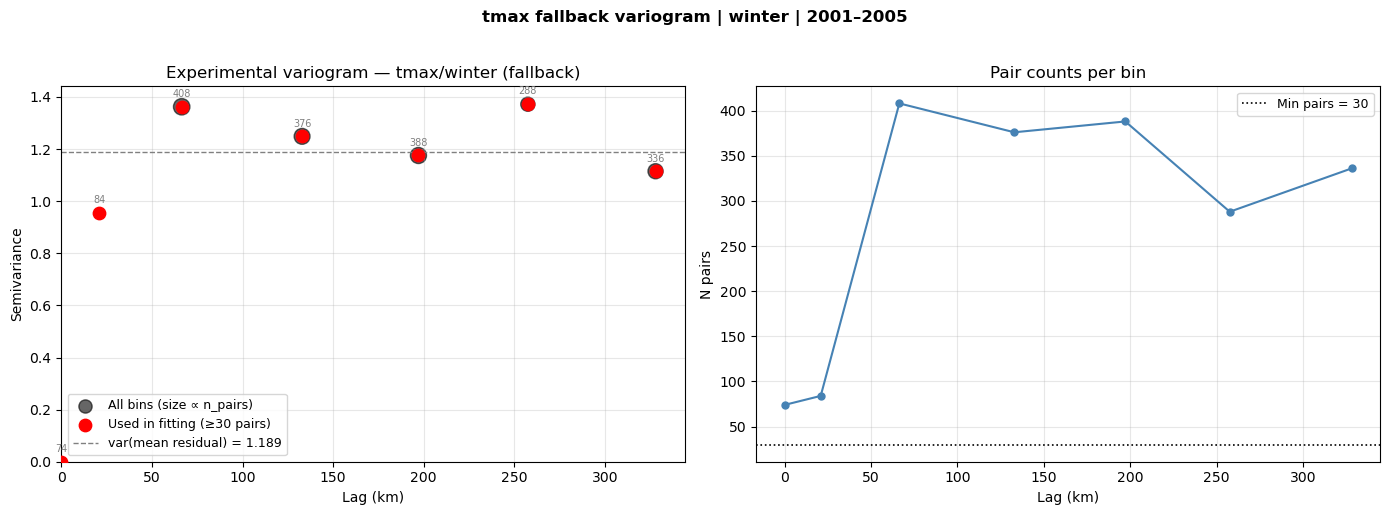

  gaussian     nug=0.0000  cc=1.2810  range=65.0km  R²=1.000  ✓
  spherical    nug=0.0000  cc=1.3146  range=65.0km  R²=1.000  ✓
  exponential  nug=0.0000  cc=1.2958  range=65.0km  R²=1.000  ✓


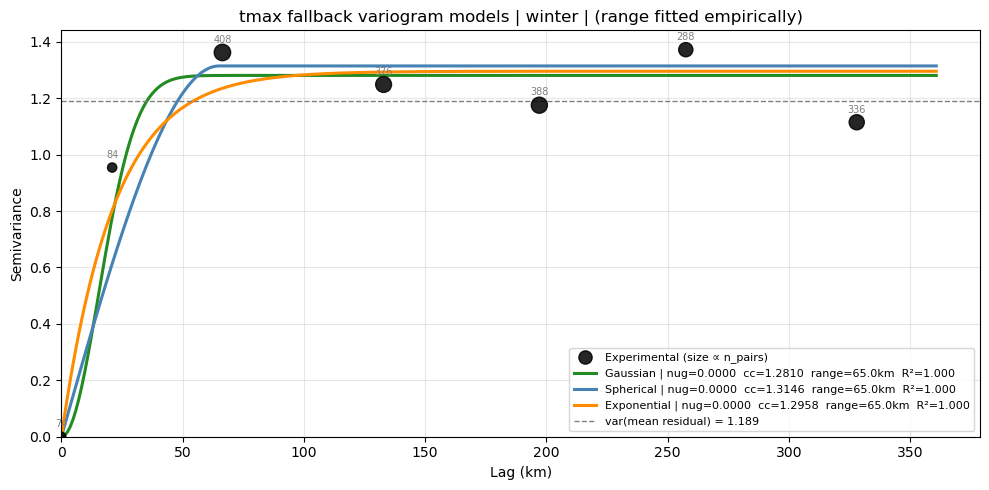


  ✓ Best model: GAUSSIAN  range=65.0km  R²=1.000
  Saved → ..\Data_Temp\Datasets\Kriging_daily\Temp\Variogram_analysis\fallback_variogram_params_daily.csv

════════════════════════════════════════════════════════════
  Fallback calibration — tmax / pre_monsoon
════════════════════════════════════════════════════════════
  Trend: intercept=34.650  slope=-0.00605 °C/m  (n=15841 station-days, 37 stations)


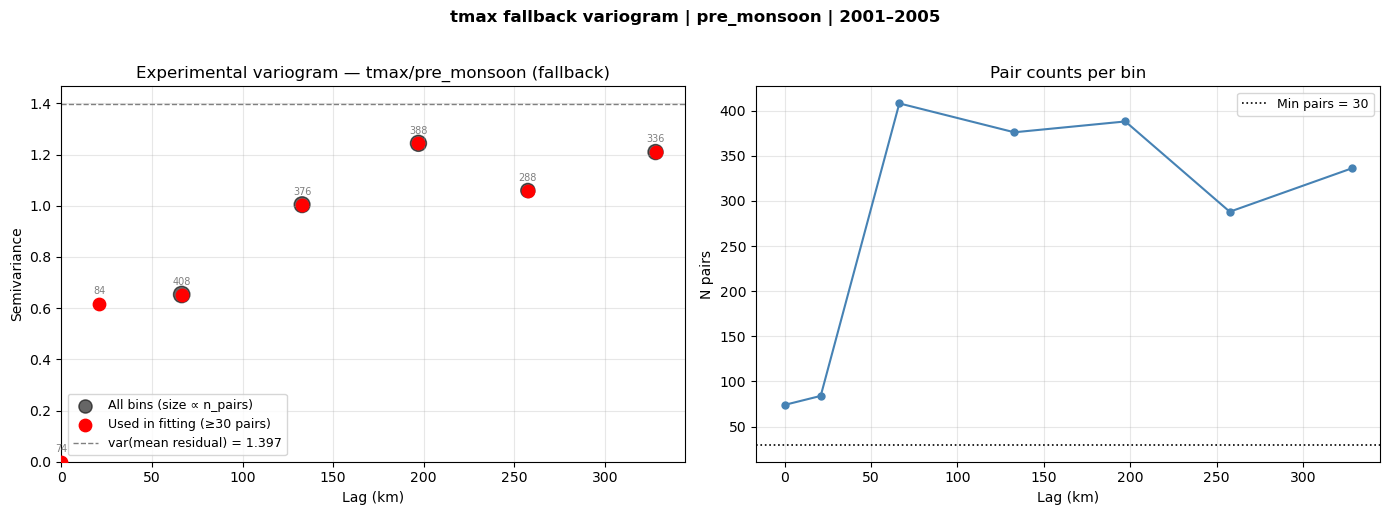

  gaussian     nug=0.0000  cc=1.0049  range=65.0km  R²=1.000  ✓
  spherical    nug=0.0000  cc=1.0249  range=65.0km  R²=1.000  ✓
  exponential  nug=0.0000  cc=1.1373  range=164.0km  R²=1.000  ✓


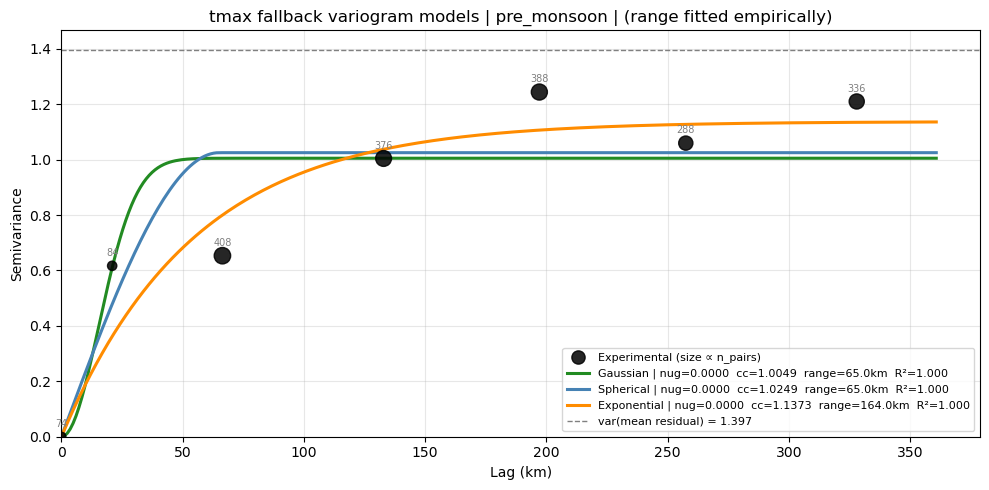


  ✓ Best model: EXPONENTIAL  range=164.0km  R²=1.000
  Saved → ..\Data_Temp\Datasets\Kriging_daily\Temp\Variogram_analysis\fallback_variogram_params_daily.csv

════════════════════════════════════════════════════════════
  Fallback calibration — tmax / monsoon
════════════════════════════════════════════════════════════
  Trend: intercept=34.323  slope=-0.00467 °C/m  (n=21125 station-days, 37 stations)


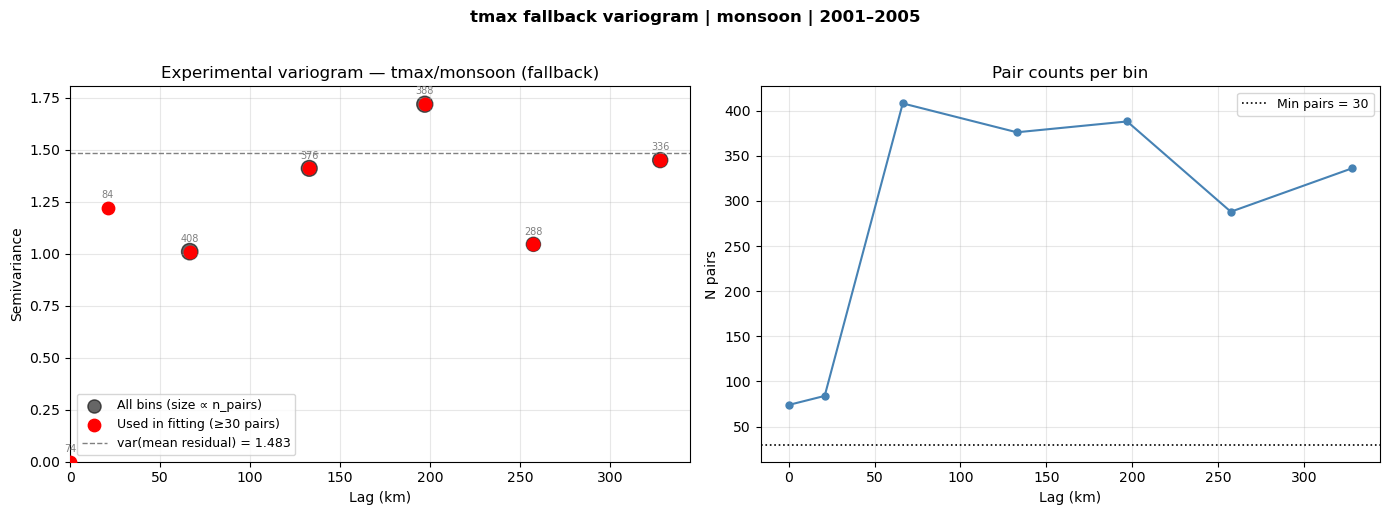

  gaussian     nug=0.0000  cc=1.3694  range=65.0km  R²=1.000  ✓
  spherical    nug=0.0000  cc=1.3990  range=65.0km  R²=1.000  ✓
  exponential  nug=0.0000  cc=1.3786  range=76.7km  R²=1.000  ✓


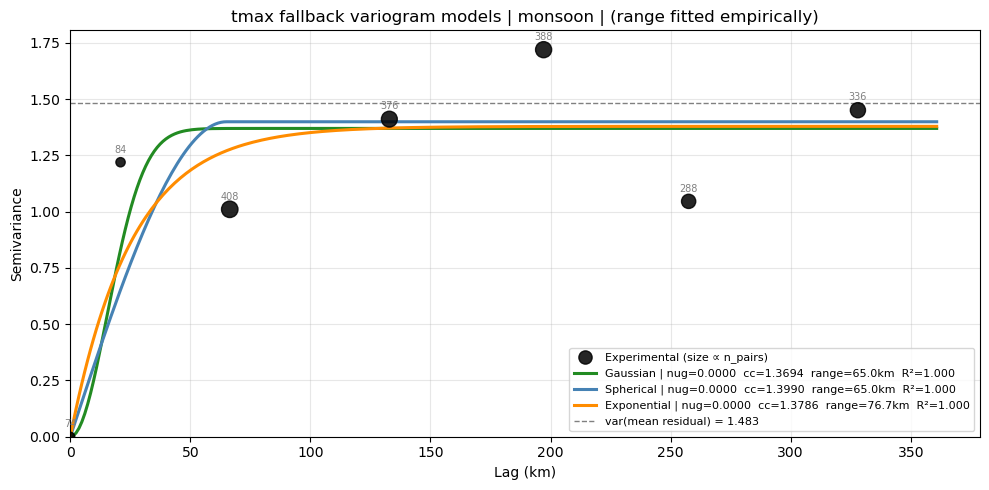


  ✓ Best model: GAUSSIAN  range=65.0km  R²=1.000
  Saved → ..\Data_Temp\Datasets\Kriging_daily\Temp\Variogram_analysis\fallback_variogram_params_daily.csv

════════════════════════════════════════════════════════════
  Fallback calibration — tmax / post_monsoon
════════════════════════════════════════════════════════════
  Trend: intercept=30.897  slope=-0.00514 °C/m  (n=10621 station-days, 37 stations)


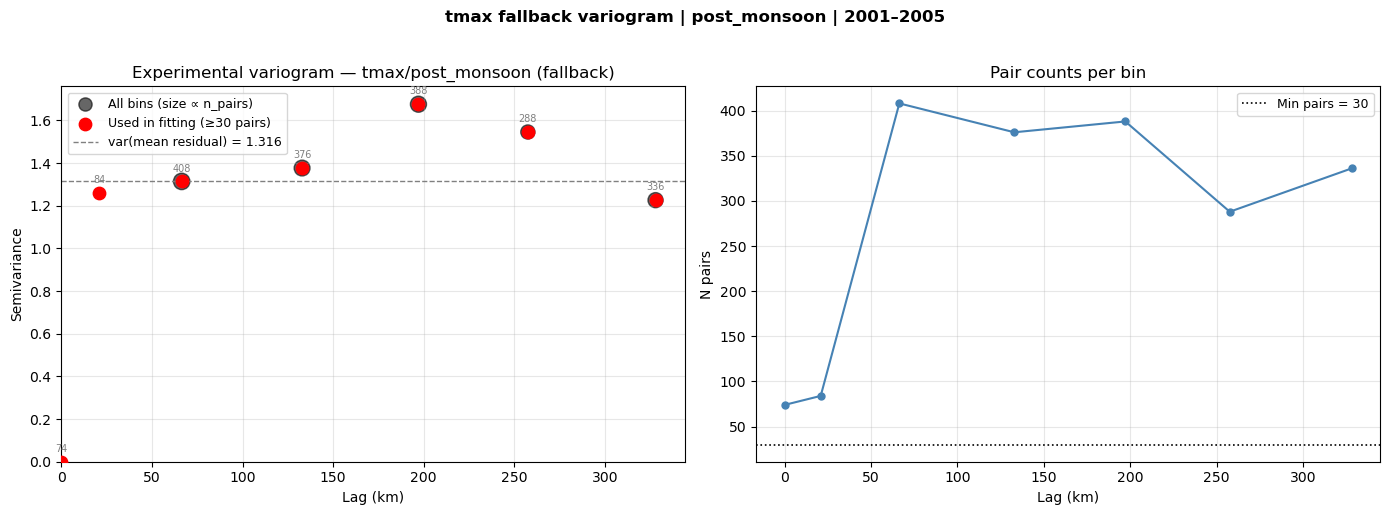

  gaussian     nug=0.0000  cc=1.4687  range=65.0km  R²=1.000  ✓
  spherical    nug=0.0000  cc=1.5041  range=65.0km  R²=1.000  ✓
  exponential  nug=0.0000  cc=1.4844  range=65.0km  R²=1.000  ✓


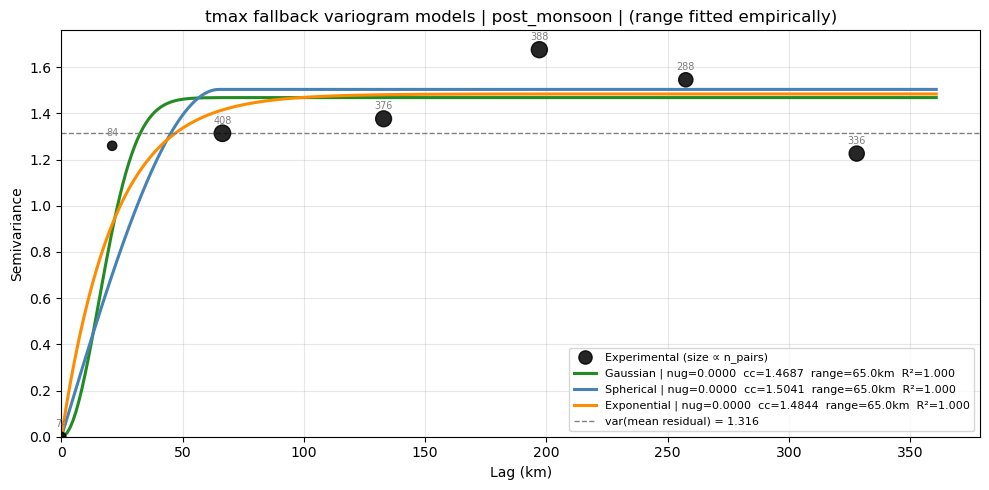


  ✓ Best model: EXPONENTIAL  range=65.0km  R²=1.000
  Saved → ..\Data_Temp\Datasets\Kriging_daily\Temp\Variogram_analysis\fallback_variogram_params_daily.csv

════════════════════════════════════════════════════════════
  tmax fallback calibration complete
════════════════════════════════════════════════════════════

############################################################
  Seasonal fallback calibration — tmin
############################################################

════════════════════════════════════════════════════════════
  Fallback calibration — tmin / winter
════════════════════════════════════════════════════════════
  Trend: intercept=10.754  slope=-0.00393 °C/m  (n=14919 station-days, 37 stations)


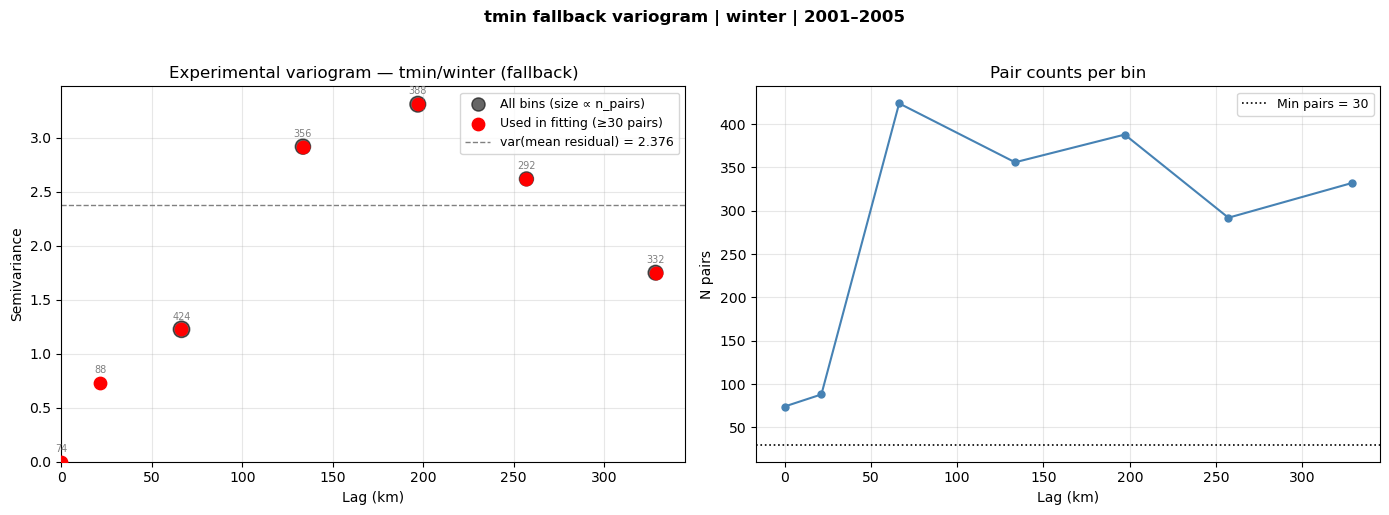

  gaussian     nug=0.0000  cc=2.2374  range=120.3km  R²=1.000  ✓
  spherical    nug=0.0000  cc=2.9367  range=190.1km  R²=1.000  ✓
  exponential  nug=0.0000  cc=3.2187  range=313.7km  R²=1.000  ⚠ SILL


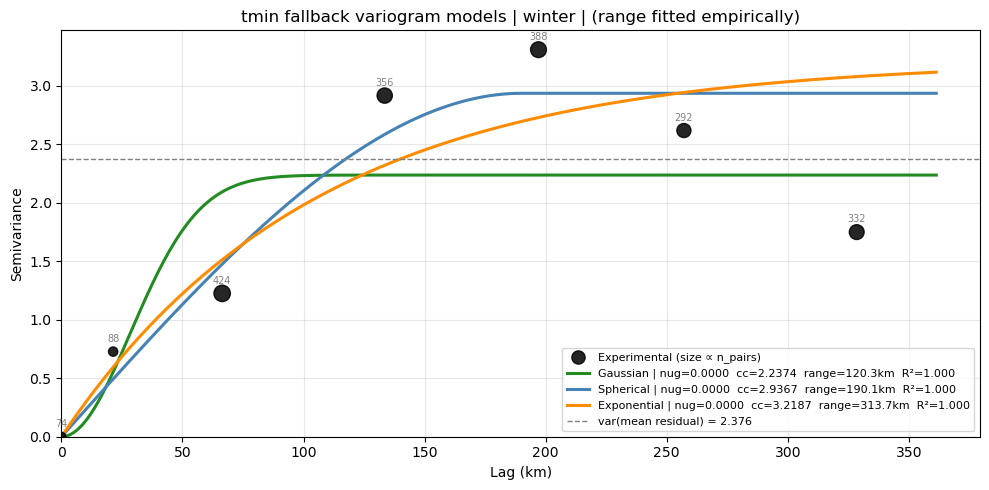


  ✓ Best model: GAUSSIAN  range=120.3km  R²=1.000
  Saved → ..\Data_Temp\Datasets\Kriging_daily\Temp\Variogram_analysis\fallback_variogram_params_daily.csv

════════════════════════════════════════════════════════════
  Fallback calibration — tmin / pre_monsoon
════════════════════════════════════════════════════════════
  Trend: intercept=20.660  slope=-0.00545 °C/m  (n=15080 station-days, 37 stations)


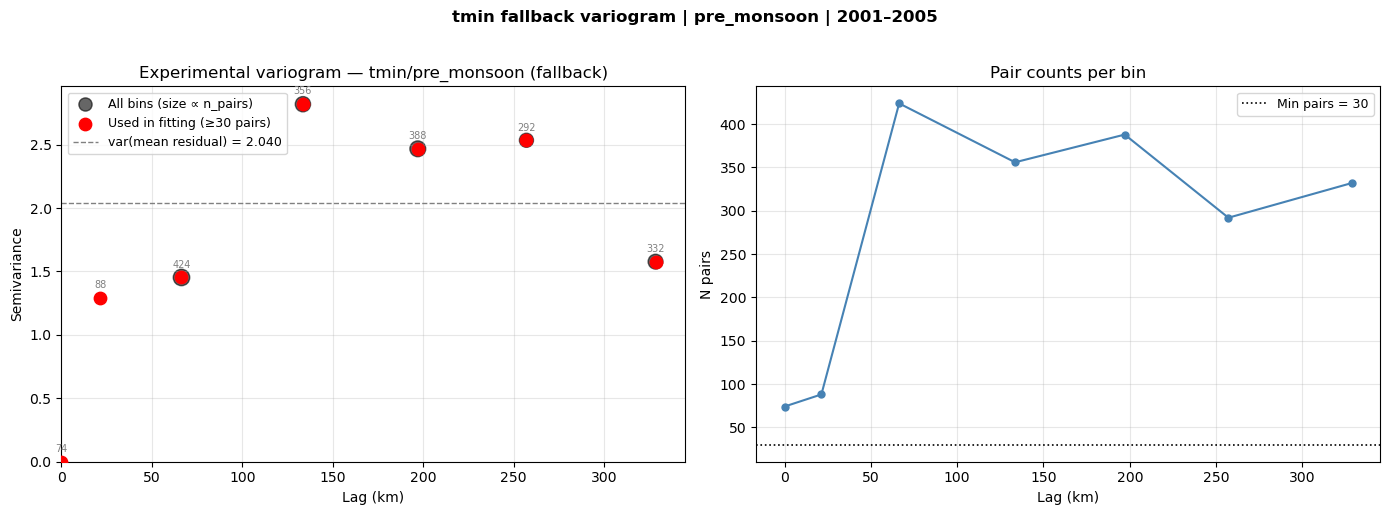

  gaussian     nug=0.0000  cc=1.8804  range=65.0km  R²=1.000  ✓
  spherical    nug=0.0000  cc=2.0035  range=65.0km  R²=1.000  ✓
  exponential  nug=0.0000  cc=1.9251  range=65.0km  R²=1.000  ✓


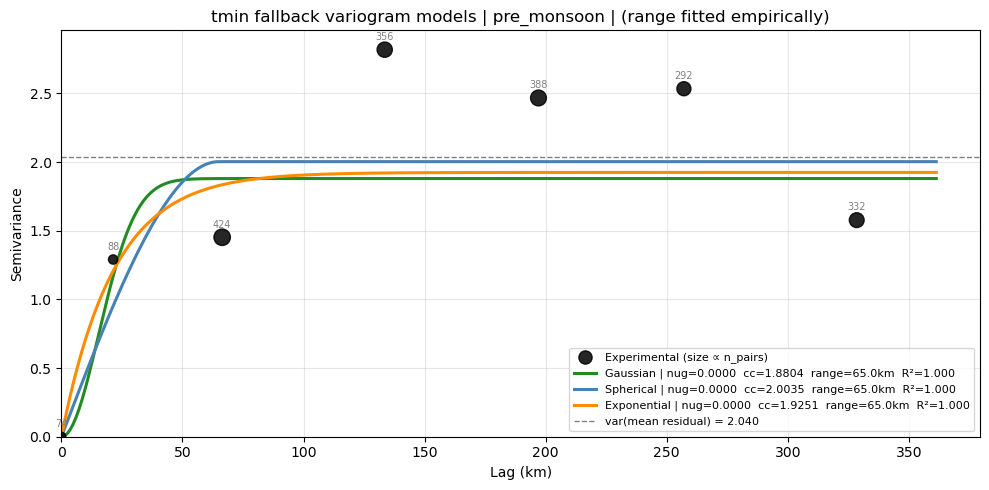


  ✓ Best model: SPHERICAL  range=65.0km  R²=1.000
  Saved → ..\Data_Temp\Datasets\Kriging_daily\Temp\Variogram_analysis\fallback_variogram_params_daily.csv

════════════════════════════════════════════════════════════
  Fallback calibration — tmin / monsoon
════════════════════════════════════════════════════════════
  Trend: intercept=25.915  slope=-0.00500 °C/m  (n=20528 station-days, 37 stations)


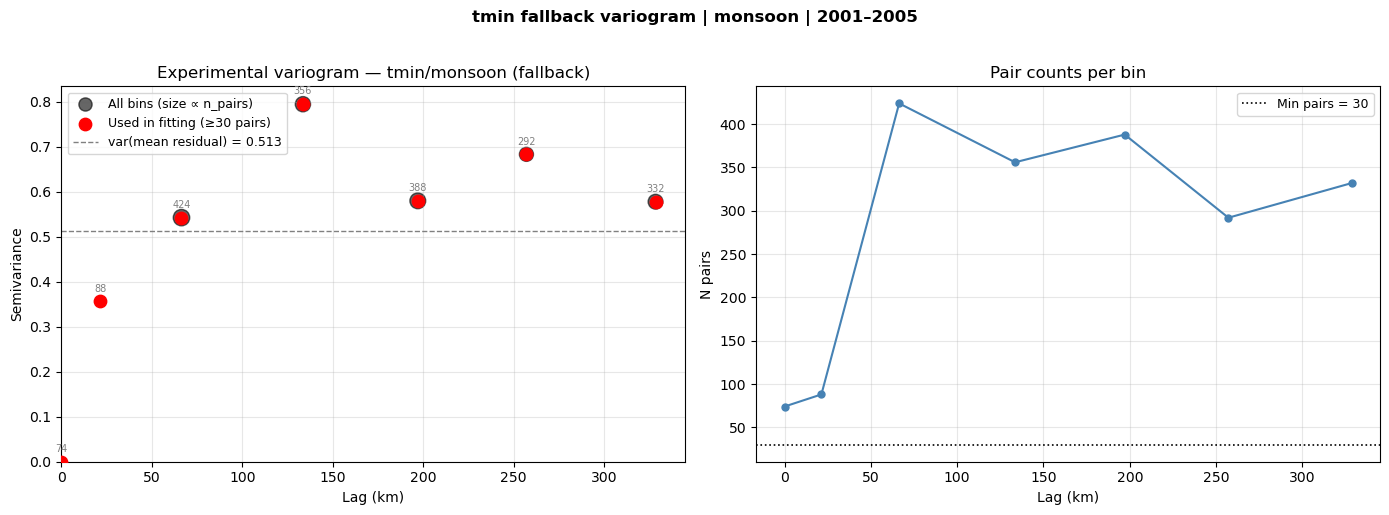

  gaussian     nug=0.0000  cc=0.5883  range=66.5km  R²=1.000  ✓
  spherical    nug=0.0000  cc=0.6277  range=65.0km  R²=1.000  ✓
  exponential  nug=0.0000  cc=0.6420  range=83.1km  R²=1.000  ✓


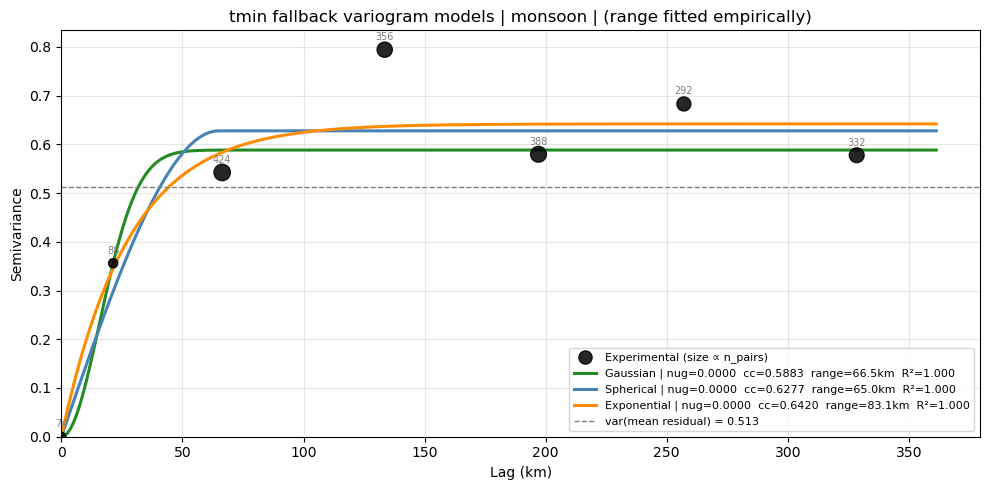


  ✓ Best model: EXPONENTIAL  range=83.1km  R²=1.000
  Saved → ..\Data_Temp\Datasets\Kriging_daily\Temp\Variogram_analysis\fallback_variogram_params_daily.csv

════════════════════════════════════════════════════════════
  Fallback calibration — tmin / post_monsoon
════════════════════════════════════════════════════════════
  Trend: intercept=18.563  slope=-0.00536 °C/m  (n=10285 station-days, 37 stations)


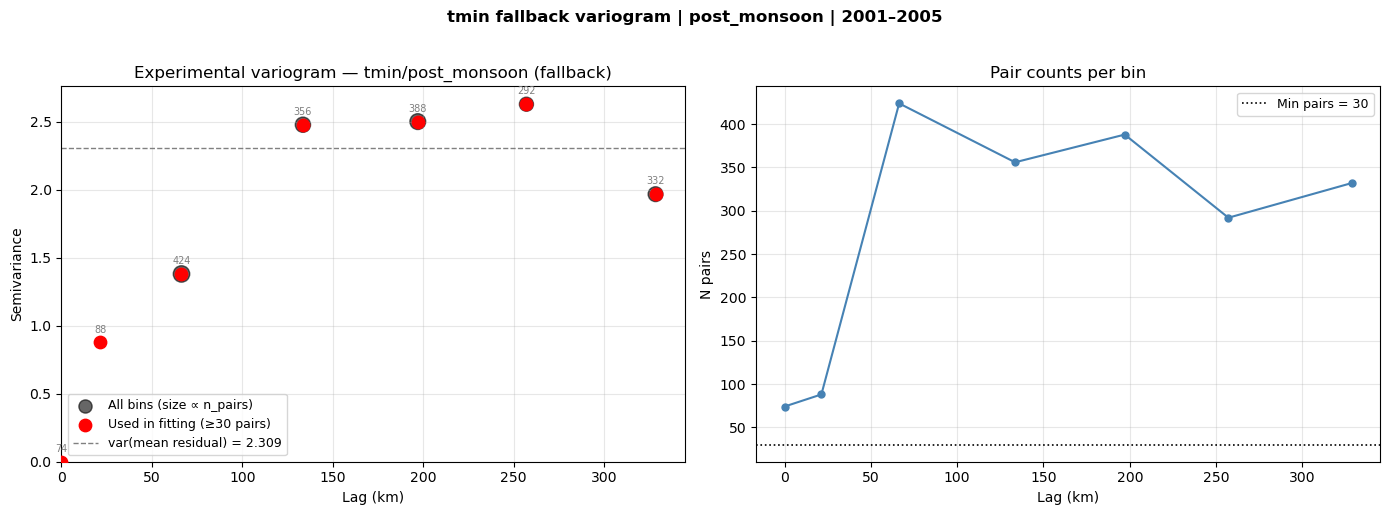

  gaussian     nug=0.0000  cc=2.3822  range=194.8km  R²=1.000  ✓
  spherical    nug=0.0000  cc=2.3840  range=132.9km  R²=1.000  ✓
  exponential  nug=0.0000  cc=2.3751  range=172.2km  R²=1.000  ✓


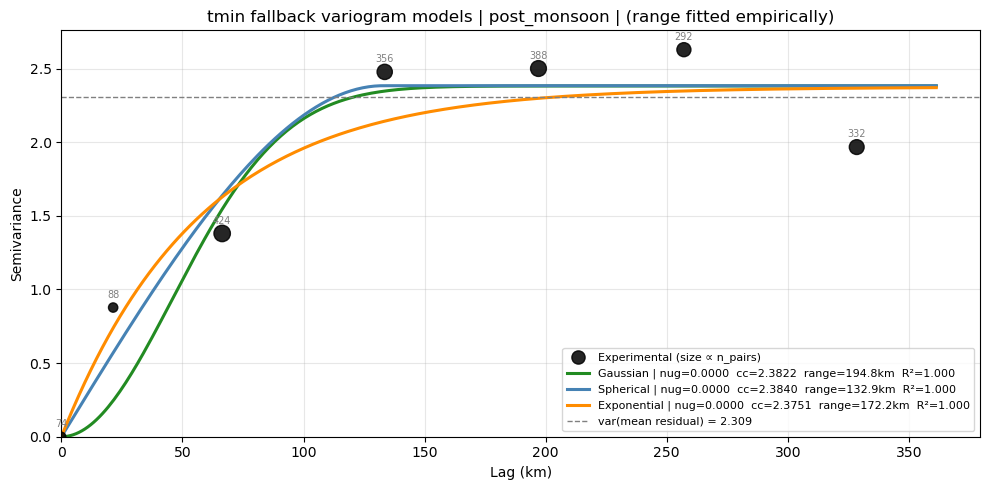


  ✓ Best model: GAUSSIAN  range=194.8km  R²=1.000
  Saved → ..\Data_Temp\Datasets\Kriging_daily\Temp\Variogram_analysis\fallback_variogram_params_daily.csv

════════════════════════════════════════════════════════════
  tmin fallback calibration complete
════════════════════════════════════════════════════════════

############################################################
  All seasonal fallback calibration complete → ..\Data_Temp\Datasets\Kriging_daily\Temp\Variogram_analysis\fallback_variogram_params_daily.csv
############################################################


In [56]:
# ── Section 6: Seasonal Trend + Fallback Variogram Calibration ────────────────
#
# Runs once per variable (tmax, tmin — independent loops, independent outputs).
# Per season: fit an elevation trend (lapse rate) on that season's pooled
# station-day data, compute residuals, then build a spatial variogram of
# those residuals to use as the seasonal fallback shape in Section 8.

import os
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist
# geostats.gamv assumed available from your existing import — unchanged usage,
# just no more geostats.nscore call.


def fit_seasonal_fallback(var_name, train_daily, geom):
    """
    var_name : 'tmax' or 'tmin'
    train_daily : insitu_data[var_name]['train_daily'] (has Elevation, from Sec 4)
    geom : geom_diagnostics[var_name] (from Section 5)
    """
    calib_data = train_daily[
        (train_daily['year'] >= calibration_start_year) &
        (train_daily['year'] <= calibration_end_year)
    ].copy()
    calib_data['season'] = calib_data['month'].map(get_season)

    print(f"\n{'#'*60}")
    print(f"  Seasonal fallback calibration — {var_name}")
    print(f"{'#'*60}")

    for season in SEASONS:
        print(f"\n{'═'*60}")
        print(f"  Fallback calibration — {var_name} / {season}")
        print(f"{'═'*60}")

        df_season = (
            calib_data[calib_data['season'] == season]
            .dropna(subset=['insitu_temp', 'Elevation'])
            .copy()
            .reset_index(drop=True)
        )

        n_stations_season = df_season['index_no'].nunique()
        if n_stations_season < min_stations_for_trend:
            print(f"  ⚠ Only {n_stations_season} stations "
                  f"(< min_stations_for_trend={min_stations_for_trend}) — skipping")
            continue

        # ── (a) Fit elevation trend on pooled station-day data ─────────────
        # Every station-day row in the season/calib window contributes —
        # not station means. More data → more stable lapse-rate estimate,
        # and no wet-day-style minimum-count-per-station gate is needed
        # here (unlike rainfall's MIN_WET_DAYS_FALLBACK, deleted per spec)
        # since a full multi-year calibration window gives each station
        # dozens to hundreds of season-days.
        intercept, slope, resid_all = fit_elevation_trend(
            df_season['Elevation'].values, df_season['insitu_temp'].values
        )
        df_season['residual'] = resid_all
        print(f"  Trend: intercept={intercept:.3f}  slope={slope:.5f} °C/m  "
              f"(n={len(df_season)} station-days, {n_stations_season} stations)")

        # ── (b) Aggregate to one residual per station for the spatial fit ──
        # Pooling all station-day residuals directly into gamv would give
        # ~n_stations × n_days points — e.g. 50 stations × 450 season-days
        # ≈ 22,500 points ≈ 2.5×10^8 pairwise distances, impractical to
        # compute and not what the original wet-day-means design intended
        # anyway. Averaging to one mean residual per station per season
        # keeps this at n_stations points (same scale as rainfall's
        # wet-day-means step) and is the direct residual analogue of it.
        station_season = (
            df_season.groupby(['index_no', 'x', 'y'])
            .agg(mean_residual=('residual', 'mean'),
                 n_days=('residual', 'count'))
            .reset_index()
        )

        if len(station_season) < min_stations_for_trend:
            print(f"  ⚠ Only {len(station_season)} station means — skipping")
            continue

        # Project to UTM km; shift x to avoid negative coords in gamv
        x_m_true, y_m = proj_utm(station_season['x'].values, station_season['y'].values)
        x_off = (
            int(np.ceil(-x_m_true.min() / 1000)) * 1000
            if x_m_true.min() < 0 else 0
        )
        station_season['x_km'] = (x_m_true + x_off) / 1000.0
        station_season['y_km'] = y_m / 1000.0

        resid_var = float(np.var(station_season['mean_residual'].values))
        if resid_var < 1e-9:
            print(f"  ⚠ Near-zero residual variance ({resid_var:.2e}) — skipping")
            continue

        # ── Omnidirectional experimental variogram of mean residuals ───────
        cluster_extent = pdist(station_season[['x_km', 'y_km']].values).max()
        lag_cap        = cluster_extent / 2.0

        lag_exp, gamma_exp, n_pairs = geostats.gamv(
            station_season, 'x_km', 'y_km', 'mean_residual',
            GAMV_TRIM_LO, GAMV_TRIM_HI,
            geom['LAG_DIST'], geom['LAG_TOL'], geom['N_LAG'],
            0, 90, BANDWH, isill=0
        )

        valid_bins = (
            (n_pairs >= geom['MIN_PAIRS']) &
            (lag_exp <= lag_cap) &
            np.isfinite(gamma_exp)
        )
        lag_fit    = lag_exp[valid_bins]
        gamma_fit  = gamma_exp[valid_bins]
        npairs_fit = n_pairs[valid_bins]

        if len(lag_fit) < 3:
            print(f"  ⚠ Only {len(lag_fit)} valid bins — skipping")
            continue

        # ── Diagnostic plot ────────────────────────────────────────────────
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        valid_all     = np.isfinite(gamma_exp) & (n_pairs > 0)
        scatter_sizes = (n_pairs / max(n_pairs.max(), 1)) * 120 + 20

        axes[0].scatter(lag_exp[valid_all], gamma_exp[valid_all],
                        s=scatter_sizes[valid_all], color='black', alpha=0.6,
                        label='All bins (size ∝ n_pairs)')
        axes[0].scatter(lag_fit, gamma_fit, s=80, color='red', zorder=5,
                        label=f"Used in fitting (≥{geom['MIN_PAIRS']} pairs)")
        for h, g, n in zip(lag_fit, gamma_fit, npairs_fit):
            axes[0].annotate(str(int(n)), (h, g),
                             textcoords='offset points', xytext=(0, 7),
                             ha='center', fontsize=7, color='gray')
        # Reference line at var(mean_residual), not 1.0 — no NSCORE here,
        # so there's no unit-variance guarantee to draw a fixed sill at.
        axes[0].axhline(resid_var, color='gray', linestyle='--', linewidth=1,
                        label=f'var(mean residual) = {resid_var:.3f}')
        axes[0].set(xlabel='Lag (km)', ylabel='Semivariance',
                    title=f'Experimental variogram — {var_name}/{season} (fallback)')
        axes[0].legend(fontsize=9); axes[0].grid(True, alpha=0.3)
        axes[0].set_xlim(left=0); axes[0].set_ylim(bottom=0)

        axes[1].plot(lag_exp[valid_all], n_pairs[valid_all], 'o-',
                     color='steelblue', linewidth=1.5, markersize=5)
        axes[1].axhline(geom['MIN_PAIRS'], color='black', linestyle=':', linewidth=1.2,
                        label=f"Min pairs = {geom['MIN_PAIRS']}")
        axes[1].set(xlabel='Lag (km)', ylabel='N pairs',
                    title='Pair counts per bin')
        axes[1].legend(fontsize=9); axes[1].grid(True, alpha=0.3)

        plt.suptitle(
            f'{var_name} fallback variogram | {season} | '
            f'{calibration_start_year}–{calibration_end_year}',
            fontweight='bold', y=1.02
        )
        plt.tight_layout(); plt.show()

        # ── Fit all three models — full 3-parameter iterative WLS ─────────
        # Range free, per original design. Bounds now scaled to residual
        # variance instead of the NSCORE unit-variance [0,0,LAG_DIST]→
        # [1.0,1.0,...] — per spec.
        target_level = sill_target * resid_var
        range_init = float(
            lag_fit[np.argmax(gamma_fit >= target_level)]
            if (gamma_fit >= target_level).any()
            else lag_fit.mean()
        )
        p0     = [0.05 * resid_var, 0.90 * resid_var, range_init]
        bounds = ([0, 0, geom['LAG_DIST']],
                  [1.5 * resid_var, 1.5 * resid_var, 2 * cluster_extent])

        # Clip p0 into bounds elementwise — must come AFTER p0/bounds are
        # both defined. range_init can land below geom['LAG_DIST'] when
        # gamma never reaches target_level and the fallback mean is pulled
        # down by short-range bins; curve_fit raises ValueError (not
        # RuntimeError) if p0 is infeasible.
        p0 = list(np.clip(p0, bounds[0], bounds[1]))

        fit_results = {}
        for model_name in MODEL_TRIAL_ORDER:
            try:
                popt, sigma_final, converged, _ = iterative_wls(
                    MODEL_FUNCTIONS[model_name],
                    lag_fit, gamma_fit, npairs_fit,
                    p0, bounds, len(lag_fit)
                )
                nugget, partial_sill, range_km = (
                    float(popt[0]), float(popt[1]), float(popt[2])
                )
                gamma_model = MODEL_FUNCTIONS[model_name](lag_fit, *popt)
                ss_res = np.sum(((gamma_fit - gamma_model) / sigma_final)**2)
                ss_tot = np.sum(((gamma_fit - gamma_fit.mean()) / sigma_final)**2)
                wls_r2 = float(1 - ss_res / ss_tot) if ss_tot > 1e-12 else np.nan

                # Sill check scaled to residual variance (30% relative
                # tolerance, same 0.3 tolerance as rainfall's absolute check,
                # now proportional instead of absolute).
                sill_flag  = abs(nugget + partial_sill - resid_var) > 0.3 * resid_var
                range_flag = range_km < geom['LAG_DIST'] or range_km > geom['domain_extent']
                fit_results[model_name] = {
                    'nugget':       nugget,
                    'partial_sill': partial_sill,
                    'range_km':     range_km,
                    'wls_r2':       wls_r2,
                    'sill_flag':    sill_flag,
                    'range_flag':   range_flag,
                }
                flags = ' '.join([
                    '⚠ SILL'  if sill_flag  else '',
                    '⚠ RANGE' if range_flag else '',
                    '✓'       if not (sill_flag or range_flag) else '',
                ]).strip()
                print(f"  {model_name:<12} nug={nugget:.4f}  cc={partial_sill:.4f}  "
                      f"range={range_km:.1f}km  R²={wls_r2:.3f}  {flags}")
            except (RuntimeError, ValueError) as e:
                print(f"  {model_name:<12} FAILED — {e}")

        if not fit_results:
            print(f"  ⚠ All models failed — skipping season")
            continue

        # ── Visual comparison ──────────────────────────────────────────────
        h_plot = np.linspace(0, lag_fit.max() * 1.1, 300)
        fig, ax = plt.subplots(figsize=(10, 5))

        ss2 = (npairs_fit / npairs_fit.max()) * 120 + 20
        ax.scatter(lag_fit, gamma_fit, s=ss2, color='black', zorder=5,
                   label='Experimental (size ∝ n_pairs)', alpha=0.85)
        for h, g, n in zip(lag_fit, gamma_fit, npairs_fit):
            ax.annotate(str(int(n)), (h, g),
                        textcoords='offset points', xytext=(0, 7),
                        ha='center', fontsize=7, color='gray')

        for model_name, res in fit_results.items():
            gamma_curve = MODEL_FUNCTIONS[model_name](
                h_plot, res['nugget'], res['partial_sill'], res['range_km']
            )
            ax.plot(h_plot, gamma_curve, color=COLORS[model_name], linewidth=2.2,
                    label=(f"{model_name.capitalize()} | "
                           f"nug={res['nugget']:.4f}  cc={res['partial_sill']:.4f}  "
                           f"range={res['range_km']:.1f}km  R²={res['wls_r2']:.3f}"))

        ax.axhline(resid_var, color='gray', linestyle='--', linewidth=1,
                   label=f'var(mean residual) = {resid_var:.3f}')
        ax.set(xlabel='Lag (km)', ylabel='Semivariance',
               title=(f'{var_name} fallback variogram models | {season} | '
                      f'(range fitted empirically)'))
        ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
        ax.set_xlim(left=0); ax.set_ylim(bottom=0)
        plt.tight_layout(); plt.show()

        # ── Select best model ──────────────────────────────────────────────
        qualified = {
            m: r for m, r in fit_results.items()
            if not r['sill_flag'] and not r['range_flag']
        }
        if not qualified:
            qualified = {m: r for m, r in fit_results.items() if not r['range_flag']}
        if not qualified:
            qualified = fit_results
        best_model = max(qualified, key=lambda m: qualified[m]['wls_r2'])
        best       = fit_results[best_model]
        print(f"\n  ✓ Best model: {best_model.upper()}  "
              f"range={best['range_km']:.1f}km  R²={best['wls_r2']:.3f}")

        # ── Save ────────────────────────────────────────────────────────────
        row = {
            'variable':           var_name,
            'season':             season,
            'n_stations':         len(station_season),
            'calib_start':        calibration_start_year,
            'calib_end':          calibration_end_year,
            'model_type':         best_model,
            'nugget':             round(best['nugget'],       6),
            'partial_sill':       round(best['partial_sill'], 6),
            'range_km':           round(best['range_km'],     3),
            'wls_r2':             round(best['wls_r2'],       6),
            'trend_intercept':    round(intercept, 6),
            'trend_slope':        round(slope, 8),
        }
        header = not os.path.exists(FALLBACK_PARAMS_CSV)
        pd.DataFrame([row]).to_csv(
            FALLBACK_PARAMS_CSV, mode='a', header=header, index=False
        )
        print(f"  Saved → {FALLBACK_PARAMS_CSV}")

    print(f"\n{'═'*60}")
    print(f"  {var_name} fallback calibration complete")
    print(f"{'═'*60}")


# ── Run per variable ─────────────────────────────────────────────────────────
for var_name in VARIABLE_CONFIGS:
    fit_seasonal_fallback(
        var_name,
        insitu_data[var_name]['train_daily'],
        geom_diagnostics[var_name],
    )

print(f"\n{'#'*60}")
print(f"  All seasonal fallback calibration complete → {FALLBACK_PARAMS_CSV}")
print(f"{'#'*60}")

In [57]:
# %%
# ── Section 7: Grid Setup ─────────────────────────────────────────────────────
# Same UTM grid + WGS84 output profile derivation as rainfall, plus one
# addition: reproject the DEM onto that same UTM grid, once, up front. This
# becomes dem_grid_utm — the array Section 8 adds the seasonal trend onto
# every day via predict_trend(intercept, slope, dem_grid_utm).

with rasterio.open(template_wgs84_path) as tmp:
    dst_crs = 'EPSG:32645'
    transform_utm, width_utm, height_utm = calculate_default_transform(
        tmp.crs, dst_crs, tmp.width, tmp.height, *tmp.bounds
    )
    out_profile_wgs84 = tmp.profile.copy()

# 1D coordinate vectors for PyKrige (in metres, grid_y south→north)
grid_x = np.linspace(
    transform_utm[2],
    transform_utm[2] + (width_utm  * transform_utm[0]),
    width_utm
)
grid_y = np.linspace(
    transform_utm[5] + (height_utm * transform_utm[4]),
    transform_utm[5],
    height_utm
)

# ── Reproject DEM onto the UTM kriging grid ────────────────────────────────
# Bilinear — DEM is continuous elevation, matching the resampling used for
# the final WGS84 raster reprojection below. Result is in rasterio top-down
# row order, matching kmap_flipped (post-np.flipud) from the kriging path,
# so the two can be added directly in Section 8 with no further flip.
dem_grid_utm = np.full((height_utm, width_utm), np.nan, dtype='float32')

with rasterio.open(dem_path) as dem_ds:
    reproject(
        source        = rasterio.band(dem_ds, 1),
        destination   = dem_grid_utm,
        src_transform = dem_ds.transform,
        src_crs       = dem_ds.crs,
        dst_transform = transform_utm,
        dst_crs       = dst_crs,
        resampling    = Resampling.bilinear,
    )

n_dem_nan = int(np.isnan(dem_grid_utm).sum())
if n_dem_nan:
    print(f"  ⚠ {n_dem_nan} pixels in the reprojected DEM grid are NaN "
          f"(source nodata or outside DEM extent) — trend reconstruction "
          f"will be NaN at these pixels every day.")

In [58]:
# %%
# ── Section 8: Daily Kriging Loop (per variable) ──────────────────────────────

fallback_params_df = (
    pd.read_csv(FALLBACK_PARAMS_CSV)
    # Guard against re-running Section 6 without clearing the CSV first —
    # keep 'last' so a fresher rerun wins over a stale duplicate row.
    .drop_duplicates(subset=['variable', 'season'], keep='last')
    .set_index(['variable', 'season'])
)

# ── Per-variable, per-season fixed-range variogram wrappers + trend grids ─────
# Trend is SEASONAL-FIXED, reused daily rather than refit per day. This
# resolves the per-day-vs-seasonal decision left open in the original spec:
# Section 6 only ever produced one trend_intercept/trend_slope per
# (variable, season) and that went unchallenged, so Section 8 reuses those
# fitted values instead of reopening the question. If per-day lapse rates
# are actually wanted, flag it — that's a real design fork, not a small edit.

seasonal_range_km    = {v: {} for v in VARIABLE_CONFIGS}
seasonal_fixed_funcs = {v: {} for v in VARIABLE_CONFIGS}
seasonal_trend_grid  = {v: {} for v in VARIABLE_CONFIGS}   # (intercept, slope, grid) or None

for var_name in VARIABLE_CONFIGS:
    for season in SEASONS:
        key = (var_name, season)
        if key in fallback_params_df.index:
            row       = fallback_params_df.loc[key]
            rng       = float(row['range_km'])
            intercept = float(row['trend_intercept'])
            slope     = float(row['trend_slope'])
        else:
            # No calibrated trend/range for this (variable, season) —
            # Section 6 had too few stations or every model failed. No
            # seasonal lapse rate exists to reuse; the daily loop falls
            # back further, per-day, only when this triggers.
            rng, intercept, slope = fix_range_fallback_km, None, None
            print(f"  ⚠ No fallback params for {var_name}/{season} — "
                  f"range defaults to {fix_range_fallback_km} km, trend "
                  f"will be refit per-day as a last resort.")
        seasonal_range_km[var_name][season]    = rng
        seasonal_fixed_funcs[var_name][season] = make_fixed_range_funcs(rng)
        seasonal_trend_grid[var_name][season] = (
            (intercept, slope, predict_trend(intercept, slope, dem_grid_utm))
            if intercept is not None else None
        )

print("\n  Seasonal ranges + trends loaded for per-day use:")
for var_name in VARIABLE_CONFIGS:
    for season in SEASONS:
        rng = seasonal_range_km[var_name][season]
        src = "empirical" if seasonal_trend_grid[var_name][season] is not None else "default/no-trend"
        print(f"    {var_name:<5} {season:<16} {rng:.1f} km  ({src})")

# ── Output subfolders, one per variable ─────────────────────────────────────
for var_name in VARIABLE_CONFIGS:
    os.makedirs(os.path.join(output_dir, var_name), exist_ok=True)

target_dates = pd.date_range(start=krig_start_day, end=krig_end_day, freq='D')
log_rows     = []

utm_meta = {
    'driver': 'GTiff', 'height': height_utm, 'width': width_utm,
    'count': 1, 'dtype': 'float32', 'crs': dst_crs,
    'transform': transform_utm, 'nodata': nodata_out,
}

for date in target_dates:
    date_str = date.strftime('%Y%m%d')
    season   = get_season(date.month)

    day_grids = {}   # var_name -> reconstructed grid (NaN = missing), for tmax/tmin check
    day_rows  = []   # this day's rows, violation count patched in after both variables

    for var_name in VARIABLE_CONFIGS:
        geom          = geom_diagnostics[var_name]
        train_daily   = insitu_data[var_name]['train_daily']
        temp_utm_path = os.path.join(temp_dir, f"{var_name}_utm.tif")

        # ── Extract today's data for this variable ─────────────────────────
        df_d = train_daily[
            (train_daily['year']  == date.year)  &
            (train_daily['month'] == date.month) &
            (train_daily['day']   == date.day)
        ].dropna(subset=['insitu_temp', 'Elevation']).copy()

        n_available = len(df_d)

        method_used       = None
        model_used        = ''
        nugget_log        = np.nan
        partial_sill_log  = np.nan

        season_range_km   = seasonal_range_km[var_name][season]
        fixed_funcs_today = seasonal_fixed_funcs[var_name][season]
        precomputed_trend = seasonal_trend_grid[var_name][season]

        # ── Resolve today's trend (intercept, slope, trend_grid) ───────────
        if precomputed_trend is not None:
            trend_intercept, trend_slope, trend_grid = precomputed_trend
        elif n_available >= min_stations_for_trend:
            # Last-resort per-day fit — only reached when Section 6 produced
            # no seasonal trend at all for this (variable, season).
            trend_intercept, trend_slope, _ = fit_elevation_trend(
                df_d['Elevation'].values, df_d['insitu_temp'].values
            )
            trend_grid = predict_trend(trend_intercept, trend_slope, dem_grid_utm)
        elif n_available > 0:
            # Not even enough for a per-day trend — flat, elevation-blind
            # reconstruction from today's mean. Degrades gracefully rather
            # than crashing; watch the log's method/n_stations_used columns
            # for how often this triggers.
            trend_intercept = float(df_d['insitu_temp'].mean())
            trend_slope     = 0.0
            trend_grid      = np.full((height_utm, width_utm), trend_intercept, dtype='float32')
        else:
            trend_intercept = np.nan
            trend_slope     = np.nan
            trend_grid      = np.full((height_utm, width_utm), np.nan, dtype='float32')

        df_d['residual'] = (
            df_d['insitu_temp'] - (trend_intercept + trend_slope * df_d['Elevation'])
            if n_available > 0 else np.nan
        )

        # ────────────────────────────────────────────────────────────────
        # BRANCH A: no / insufficient stations → trend-only, no kriging
        # ────────────────────────────────────────────────────────────────
        if n_available == 0:
            recon_grid  = trend_grid
            method_used = 'no_data'
        elif n_available < geom['MIN_STATIONS_FOR_RESIDUAL_VGM']:
            recon_grid  = trend_grid
            method_used = 'trend_only'
        # ────────────────────────────────────────────────────────────────
        # BRANCH B: sufficient stations → attempt residual kriging
        # ────────────────────────────────────────────────────────────────
        else:
            resid_var_today = float(np.var(df_d['residual'].values))

            x_m, y_m = proj_utm(df_d['x'].values, df_d['y'].values)
            x_off = (
                int(np.ceil(-x_m.min() / 1000)) * 1000
                if x_m.min() < 0 else 0
            )
            x_km = (x_m + x_off) / 1000.0
            y_km = y_m / 1000.0

            gamv_ok = False
            if resid_var_today > 1e-9:
                try:
                    lag_exp, gamma_exp, n_pairs = geostats.gamv(
                        df_d.assign(x_km=x_km, y_km=y_km),
                        'x_km', 'y_km', 'residual',
                        GAMV_TRIM_LO, GAMV_TRIM_HI,
                        geom['LAG_DIST'], geom['LAG_TOL'], geom['N_LAG'],
                        0, 90, BANDWH, isill=0
                    )
                    lag_cap    = pdist(np.column_stack([x_km, y_km])).max() / 2.0
                    valid_bins = (
                        (n_pairs >= geom['MIN_PAIRS']) &
                        (lag_exp <= lag_cap) &
                        np.isfinite(gamma_exp)
                    )
                    lag_fit    = lag_exp[valid_bins]
                    gamma_fit  = gamma_exp[valid_bins]
                    npairs_fit = n_pairs[valid_bins]
                    gamv_ok    = len(lag_fit) >= 3
                except Exception:
                    gamv_ok = False

            # Bounds scaled to TODAY's residual variance — computed fresh
            # per day (not reusing Section 6's pooled calibration variance),
            # since a single day's spread can differ meaningfully from the
            # multi-year pooled value.
            nugget_use = partial_sill_use = model_use = None

            if gamv_ok:
                p0_today     = (0.05 * resid_var_today, 0.90 * resid_var_today)
                bounds_today = ([0.0, 0.0], [1.5 * resid_var_today, 1.5 * resid_var_today])
                for model_name in MODEL_TRIAL_ORDER:
                    try:
                        nugget, partial_sill, wls_r2 = fit_fixed_range_wls(
                            fixed_funcs_today, model_name,
                            lag_fit, gamma_fit, npairs_fit,
                            p0=p0_today, bounds=bounds_today
                        )
                        if wls_r2 >= 0.0 and partial_sill > 0:
                            nugget_use       = nugget
                            partial_sill_use = partial_sill
                            model_use        = model_name
                            method_used      = 'kriging_per_day'
                            break
                    except (RuntimeError, ValueError):
                        continue

            # ── Fall back to seasonal params if per-day fit failed ─────────
            if model_use is None:
                key = (var_name, season)
                if key in fallback_params_df.index:
                    fp                = fallback_params_df.loc[key]
                    nugget_use        = float(fp['nugget'])
                    partial_sill_use  = float(fp['partial_sill'])
                    model_use         = fp['model_type']
                    method_used       = 'kriging_seasonal_fallback'
                else:
                    recon_grid  = trend_grid
                    method_used = 'trend_only_no_fallback'

            # ── Ordinary kriging on residuals directly (no NSCORE) ─────────
            if model_use is not None:
                ok_model = OrdinaryKriging(
                    x_m, y_m, df_d['residual'].values,
                    variogram_model=model_use,
                    variogram_parameters={
                        'sill':   partial_sill_use,
                        'range':  season_range_km * 1000.0,   # km → m
                        'nugget': nugget_use,
                    },
                    verbose=False,
                    enable_plotting=False,
                )
                kmap, _ = ok_model.execute('grid', grid_x, grid_y, backend='vectorized')
                kmap_flipped = np.flipud(kmap.data)

                # Reconstruct: kriged residual + seasonal trend surface.
                # No clip — sub-zero / near-freezing values are valid.
                recon_grid = kmap_flipped + trend_grid

                nugget_log       = nugget_use
                partial_sill_log = partial_sill_use
                model_used       = model_use

        day_grids[var_name] = recon_grid   # keep NaN as the missing-data marker

        # ── Save GeoTIFF ────────────────────────────────────────────────
        with rasterio.open(temp_utm_path, 'w', **utm_meta) as dst:
            dst.write(np.nan_to_num(recon_grid, nan=nodata_out).astype('float32'), 1)

        final_path = os.path.join(output_dir, var_name, f"{var_name}_{date_str}.tif")
        with rasterio.open(temp_utm_path) as src:
            with rasterio.open(final_path, 'w', **out_profile_wgs84) as dst:
                reproject(
                    source        = rasterio.band(src, 1),
                    destination   = rasterio.band(dst, 1),
                    src_transform = src.transform,
                    src_crs       = src.crs,
                    dst_transform = dst.transform,
                    dst_crs       = dst.crs,
                    resampling    = Resampling.bilinear,
                )

        day_rows.append({
            'date':            date_str,
            'variable':        var_name,
            'season':          season,
            'n_stations_used': n_available,
            'method':          method_used,
            'model':           model_used,
            'range_km':        round(season_range_km, 1),
            'nugget':          round(nugget_log,       4) if not np.isnan(nugget_log)       else '',
            'partial_sill':    round(partial_sill_log, 4) if not np.isnan(partial_sill_log) else '',
            'trend_intercept': round(trend_intercept, 4) if not np.isnan(trend_intercept) else '',
            'trend_slope':     round(trend_slope, 6)     if not np.isnan(trend_slope)     else '',
        })

    # ── Day-level tmax ≥ tmin physical-consistency check ────────────────────
    # Logged, not corrected. Violation = tmax_grid < tmin_grid, pixelwise,
    # over pixels where both grids have real (non-NaN) values that day.
    if 'tmax' in day_grids and 'tmin' in day_grids:
        both_valid = np.isfinite(day_grids['tmax']) & np.isfinite(day_grids['tmin'])
        violations = int(np.sum((day_grids['tmax'] < day_grids['tmin']) & both_valid))
    else:
        violations = np.nan

    for row in day_rows:
        row['tmax_tmin_violations'] = violations
    log_rows.extend(day_rows)

    if date.day == 1:
        summary = "  ".join(f"{r['variable']}: n={r['n_stations_used']} {r['method']}" for r in day_rows)
        print(f"  {date_str}  {summary}  violations={violations}")

# ── Save log and print summary ────────────────────────────────────────────────
log_df = pd.DataFrame(log_rows)
log_df.to_csv(LOG_CSV, index=False)

print(f"\n{'═'*60}")
print(f"  Daily kriging complete")
print(f"  Total day-variable rows : {len(log_df)}")
for var_name in VARIABLE_CONFIGS:
    sub = log_df[log_df['variable'] == var_name]
    print(f"\n  {var_name} method breakdown:")
    for method, count in sub['method'].value_counts().items():
        pct = count / len(sub) * 100
        print(f"    {method:<30} {count:>5}  ({pct:.1f}%)")

violation_days   = log_df.drop_duplicates('date')['tmax_tmin_violations']
n_valid_days     = violation_days.notna().sum()
n_violation_days = (violation_days > 0).sum()
print(f"\n  Days with ≥1 tmax<tmin pixel violation: {n_violation_days} / {n_valid_days}")
if (violation_days > 0).any():
    print(f"  Mean violated pixels per day (where >0): {violation_days[violation_days > 0].mean():.1f}")
else:
    print(f"  Mean violated pixels per day: n/a (no violations)")
print(f"\n  Log saved → {LOG_CSV}")
print(f"{'═'*60}")


  Seasonal ranges + trends loaded for per-day use:
    tmax  winter           65.0 km  (empirical)
    tmax  pre_monsoon      164.0 km  (empirical)
    tmax  monsoon          65.0 km  (empirical)
    tmax  post_monsoon     65.0 km  (empirical)
    tmin  winter           120.3 km  (empirical)
    tmin  pre_monsoon      65.0 km  (empirical)
    tmin  monsoon          83.1 km  (empirical)
    tmin  post_monsoon     194.8 km  (empirical)
  20010101  tmax: n=34 kriging_per_day  tmin: n=31 kriging_per_day  violations=50
  20010201  tmax: n=33 kriging_per_day  tmin: n=30 kriging_per_day  violations=178
  20010301  tmax: n=33 kriging_per_day  tmin: n=30 kriging_per_day  violations=554
  20010401  tmax: n=34 kriging_per_day  tmin: n=31 kriging_per_day  violations=1699
  20010501  tmax: n=33 kriging_per_day  tmin: n=30 kriging_per_day  violations=313
  20010601  tmax: n=34 kriging_per_day  tmin: n=30 kriging_per_day  violations=19
  20010701  tmax: n=33 kriging_per_day  tmin: n=30 kriging_per_d